# Compute percolation paths

## Introduction
In this tutorial, we illustrate how to compute percolation paths in a crystalline material using mofography.
Computing percolation is important for a variety of applications including, 
- calculating the Pore Limiting Diameter (PLD) of a material
- determining the accessibility of a pocket, subject to a certain probe size
- diffusion related applications.

However, computing percolation paths is highly non-trivial in periodic materials. There is quite a bit of existing theory on doing this using grids, however, mofography already abstracts this grid into a pore graph, which means we can use path finding on graphs to compute percolation paths. This will be orders of magnitude faster than grid-based methods. However, the the number of all possible paths between a pair of nodes increases exponentially with the number of nodes, hence, this approach alone is greatly limiting. Hence, mofography uses a combination of two types of pathfinding algorithms as an approximation to find all the relevant paths for most applications. By relevant, we mean that paths that are the shortest in most cases, geometrically unique basis based on the types of pockets they connect, and the one that gives us the pore limiting dia. In a nutshell, 
- For small unit cells, all simple paths between all pairs of nodes on the opposite faces of the unit cell will give us the percolation paths.
- For larger unit cells, we use a combination of Dijkstra's algorithm to find the shortest paths (which are usually the straight channel paths), usually contain the PLD. 
- Note that when we compute paths in any direction, say, 'a', we included the periodic connectivity in the other two directions, 'b' and 'c' to ensure that we are not missing any paths that are periodic in the other two directions. While looking for percolation in one direction, the molecules are allowed to go out of the unit cell in the other two directions, and then come back in. 
- We also need keep track of the internal and periodic windows along each of the paths, as these are central to determining the accessibility of the pockets.

## Contents of this tutorial
- The usual steps, read in the structure -> distance grid -> regions, maxima -> pbc -> pore graph -> store everything on rag
- Test computation of percolation paths for the given mask_thickness
- show the percolated paths as a dataframe
- filter percolated paths inaccessible to a probe of a certain size
- plot the percolation paths on the structure
- in some materials, the set mask_thickness may not be enough to find any paths if all the windows are smaller than this, so we need to iteratively reduce the mask_thickness until we find some paths. There is a functino to do this in mofography, and we will illustrate how to use it here.

## Note
- This tutorial assumes that you have already read the tutorial up to the point of computing the pore graph. If not, please refer to the previous tutorials if anything is unclear. 
- we are still working on validating the PLD calculations, if something doesn't quite match with Zeo++ or other codes, please be patient, we'll fix it in a couple of days. 

## Imports

In [1]:
import numpy as np 
import os , sys
from pathlib import Path

import dask
from dask import delayed
from dask.distributed import progress, Client 

path_to_mgr = Path('../../../mofography_general/mofography')
sys.path.append(str(path_to_mgr))
import mofography as mgr

from ase.io import read, write
import plotly.graph_objects as go

## Read in random CIF from the examples folder

In [2]:
path_to_cif  = Path('../examples/TestCIFs/NU-1000_S1.cif')
mat_atoms = read(path_to_cif)

## Compute everything up to the pore graph and store everything 

In [3]:
dgrid = mgr.dgrid_from_atoms_cpu(mat_atoms, spacing=0.5)
regions, maxima = mgr.regions_from_dgrid(dgrid, mask_thickness=0.5 )
connections = mgr.connections_from_regions_and_dgrid(regions, dgrid, maxima, mat_atoms)
maxima_radii = dgrid[tuple(maxima.T)]
pbc_groups = mgr.apply_pbc(regions, maxima, maxima_radii, mat_atoms, return_conn=True)
rag = mgr.rag_from_connections(connections, maxima)
rag = mgr.add_maxima_to_rag(rag, maxima, maxima_radii, dgrid.shape, mat_atoms)
rag = mgr.add_pbc_to_rag(rag, pbc_groups=pbc_groups)
rag.graph['dgrid'] = dgrid
rag.graph['ase_atoms'] = mat_atoms
rag.graph['connections'] = connections
rag.graph['regions'] = regions
rag.graph['maxima']=maxima

c:\Users\Public\anaconda3\envs\test\lib\site-packages\ase\utils\__init__.py:62: FutureWarning: Please use atoms.cell.cellpar() instead
  warnings.warn(warning)
c:\Users\Arun Gopalan\OneDrive - The University of Manchester\my_cloned_repos\mofography_general\mofography\docs\..\..\..\mofography_general\mofography\mofography\compute.py:382: UserWarning: Some maxima excluded as they fell inside the mask_thickness
  warnings.warn('Some maxima excluded as they fell inside the mask_thickness')
ic| regions_to_check: array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
                             18])
ic| len(outer): 18
c:\Users\Public\anaconda3\envs\test\lib\site-packages\numpy\core\shape_base.py:121: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  ary = a

## Compute percolation paths

Now we have everything needed to compute the percolation paths. If anything up to this point is unclear, please refer to the basic tutorials. Ok, in the code below, you'll notice the path_jump_cutoff parameter, this one limits the maximum length (number of edges) of the paths detected by the all possible paths part of the code. If set to None, it will set a number based on the size of the pore graph. Also, note that, although you cannot see it, this paths detection is based on all the distance and regions grids calculated and stored in the previous cell. So, if you change the mask_thickness in the regions segmentation, you will get different paths. Also, there could be a lot of paths detected for even a relatively big pore graph.

In [4]:
paths, path_windows, path_lengths = mgr.get_percolated_paths_on_rag(rag, path_jump_cutoff=None)

For direction  0
Dijkstra paths are computed for direction 0
Computing simple paths for direction 0


100%|██████████| 3/3 [00:02<00:00,  1.01it/s]


For direction  1
Dijkstra paths are computed for direction 1
Computing simple paths for direction 1


100%|██████████| 3/3 [00:02<00:00,  1.04it/s]


For direction  2
Dijkstra paths are computed for direction 2
Computing simple paths for direction 2


100%|██████████| 6/6 [00:04<00:00,  1.48it/s]


Now, let's use the built-in function to show these detected paths as a pandas dataframe

In [5]:
mgr.show_percolated_paths_as_df(paths, path_windows, path_lengths)

,paths,path_windows,path_lengths
0,"[1, 1]","[5.350078563690186, 5.27008436203003]",0
1,"[2, 2]","[5.7629673957824705, 5.458671379089355]",0
2,"[17, 17]","[5.762994575500488, 5.4586999893188475]",0
3,"[18, 18]","[4.851957302093506, 4.779248218536377]",0
3108,"[4, 1]","[2.5237693637847896, 5.27008436203003]",1
...,...,...,...
5590,"[12, 18, 16, 15, 17]","[0.9033359183490185, 2.98123850221634, 2.08731...",4
5596,"[12, 18, 16, 17, 15]","[2.702353543151203, 2.98123850221634, 2.087312...",4
5598,"[12, 18, 16, 3, 1]","[2.98123850221634, 2.7660360145568847, 2.72057...",4
5600,"[12, 18, 16, 3, 2]","[2.98123850221634, 2.7660360145568847, 2.72057...",4


you can also filter out the paths that are inaccessible to a particular probe size, meaning all the paths with at least one window smaller than the probe size will be removed. This is done using the filter_percolation_paths function. The probe size is in Angstroms. 

So that looks like this: 

In [6]:
filtered_paths, filtered_path_windows, filtered_path_lengths= mgr.filter_percolated_paths(paths, path_windows, path_lengths, probe_size=1.5)
mgr.show_percolated_paths_as_df(filtered_paths, filtered_path_windows, filtered_path_lengths)

,paths,path_windows,path_lengths
0,"[1, 1]","[5.350078563690186, 5.27008436203003]",0
1,"[2, 2]","[5.7629673957824705, 5.458671379089355]",0
2,"[17, 17]","[5.762994575500488, 5.4586999893188475]",0
3,"[18, 18]","[4.851957302093506, 4.779248218536377]",0
1452,"[4, 1]","[2.5237693637847896, 5.27008436203003]",1
...,...,...,...
3073,"[12, 18, 11, 14, 15]","[2.9585334990902887, 2.6053859838771816, 1.951...",4
3086,"[12, 18, 15, 1, 7]","[2.0791225260742183, 2.0457323121756157, 2.605...",4
3104,"[12, 18, 16, 17, 15]","[2.702353543151203, 2.98123850221634, 2.087312...",4
3106,"[12, 18, 16, 3, 1]","[2.98123850221634, 2.7660360145568847, 2.72057...",4


We can use the built-in plot_paths function to generate traces to overlay the paths on the regions segmentation and the pore structure. Let's visualize.

Note that since usually there is a large number of paths, it might be beneficial to find 'unique' paths. which in this context could be finding paths that are non isormorphic, subject to the types of the pockets they connect. 

First let's detect the pocket types like before.

In [7]:
from skimage.measure import regionprops
props = regionprops(rag.graph['regions'])
rag = mgr.add_psd_to_rag_with_pbc(rag,props, pbc_groups, bins=100, ase_atoms=mat_atoms, shape=dgrid.shape) 

In [8]:
filtered_paths = [list(l) for l in filtered_paths]

In [9]:
paths_list = mgr.find_isomorphic_path_groups(filtered_paths[:100], rag)
# [np.unique(p) for p in paths_list ]

c:\Users\Public\anaconda3\envs\test\lib\site-packages\sklearn\cluster\_agglomerative.py:1006: FutureWarning: Attribute `affinity` was deprecated in version 1.2 and will be removed in 1.4. Use `metric` instead
  warnings.warn(


In [10]:
unique_paths = [list(t) for p in paths_list for t in set(tuple(u) for u in p)]

c:\Users\Arun Gopalan\OneDrive - The University of Manchester\my_cloned_repos\mofography_general\mofography\docs\..\..\..\mofography_general\mofography\mofography\visualize.py:175: FutureWarning: arrays to stack must be passed as a "sequence" type such as list or tuple. Support for non-sequence iterables such as generators is deprecated as of NumPy 1.16 and will raise an error in the future.
  coordinates= np.vstack(map(maxima_dict.get, path))


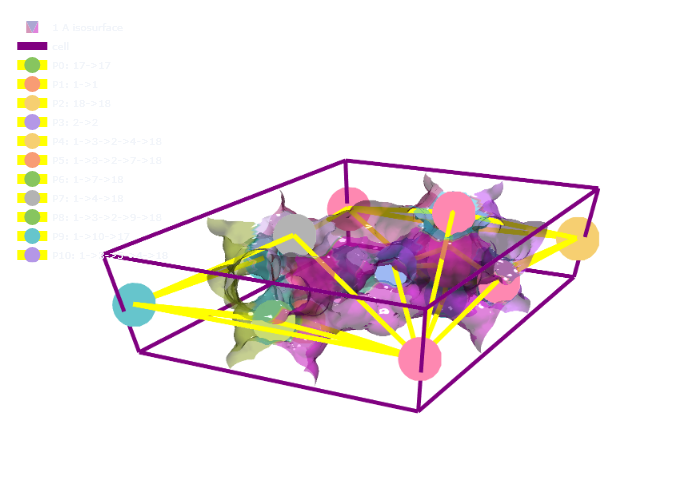

In [11]:
surface_trace = mgr.plot_surface_dgrid(dgrid, isovalue=1, ase_atoms = mat_atoms, region_labels=regions, stylize=True, opacity=0.5)
cell_trace = mgr.plot_cell(mat_atoms)

path_traces = mgr.plot_paths(rag,unique_paths, colorscale='Pastel')

fig = go.Figure(data=[surface_trace, cell_trace]+path_traces, layout=mgr.epic_layout)
fig.show(renderer='png')

## Iterative determination of percolation and PLD
For some of the materials, the set mask_thickness may not be enough to find any paths if all the windows are smaller than this, so we need to iteratively reduce the mask_thickness until we find some paths, and detect the PLD. There is a function to do this in mofography, and using it is quite simple. If you set the 'return_path_info' parameter to True, it will return the (paths, path_windows, path_lengths) for the mask_thickness at which paths were found, along with the Pore Limiting Radius.

In [12]:
pld  = mgr.get_pld_for_rag(rag, return_path_info=False)
print('Pore limiting diameter:', pld, 'angstroms')

c:\Users\Public\anaconda3\envs\test\lib\site-packages\ase\utils\__init__.py:62: FutureWarning:

Please use atoms.cell.cellpar() instead



Number of atoms in the supercell: 558
No need to make supercell
- Constructing pore graph
pore graph constructed
pB applied
- Computing percolated paths
path jump cutoff is  None
For direction  0
Dijkstra paths are computed for direction 0
Computing simple paths for direction 0


  0%|          | 0/3 [00:00<?, ?it/s]

100%|██████████| 3/3 [00:02<00:00,  1.02it/s]


For direction  1
Dijkstra paths are computed for direction 1
Computing simple paths for direction 1


100%|██████████| 3/3 [00:02<00:00,  1.01it/s]


For direction  2
Dijkstra paths are computed for direction 2
Computing simple paths for direction 2


100%|██████████| 6/6 [00:04<00:00,  1.48it/s]

Pore limiting diameter: 10.917399978637695 angstroms


if you'd like the paths information also, you can set the 'return_path_info' parameter to True.

In [14]:
mgr.get_pld_from_percolated_paths_path_windows(filtered_paths, filtered_path_windows)

10.917399978637695

In [18]:
pld, paths, path_windows, path_lengths = mgr.get_pld_for_rag(rag, return_pld_path_info=True)
print('Pore limiting diameter:', pld, 'angstroms')
mgr.show_percolated_paths_as_df(paths, path_windows, path_lengths)

c:\Users\Public\anaconda3\envs\test\lib\site-packages\ase\utils\__init__.py:62: FutureWarning:

Please use atoms.cell.cellpar() instead



Number of atoms in the supercell: 558
No need to make supercell
- Constructing pore graph
pore graph constructed
pB applied
- Computing percolated paths
path jump cutoff is  None
For direction  0
Dijkstra paths are computed for direction 0
Computing simple paths for direction 0


  0%|          | 0/3 [00:00<?, ?it/s]

100%|██████████| 3/3 [00:03<00:00,  1.00s/it]


For direction  1
Dijkstra paths are computed for direction 1
Computing simple paths for direction 1


100%|██████████| 3/3 [00:02<00:00,  1.02it/s]


For direction  2
Dijkstra paths are computed for direction 2
Computing simple paths for direction 2


100%|██████████| 6/6 [00:04<00:00,  1.44it/s]

Pore limiting diameter: 10.917399978637695 angstroms


,paths,path_windows,path_lengths
0,"[1, 1]","[5.350078563690186, 5.27008436203003]",0
1,"[2, 2]","[5.7629673957824705, 5.458671379089355]",0
2,"[17, 17]","[5.762994575500488, 5.4586999893188475]",0
3,"[18, 18]","[4.851957302093506, 4.779248218536377]",0
3108,"[4, 1]","[2.5237693637847896, 5.27008436203003]",1
...,...,...,...
5590,"[12, 18, 16, 15, 17]","[0.9033359183490185, 2.98123850221634, 2.08731...",4
5596,"[12, 18, 16, 17, 15]","[2.702353543151203, 2.98123850221634, 2.087312...",4
5598,"[12, 18, 16, 3, 1]","[2.98123850221634, 2.7660360145568847, 2.72057...",4
5600,"[12, 18, 16, 3, 2]","[2.98123850221634, 2.7660360145568847, 2.72057...",4


## Conclusion
In this tutorial, we illustrated how to compute percolation paths in a crystalline material using mofography. We also illustrated how to iteratively determine the percolation paths and the Pore Limiting Diameter (PLD) for a given material if the current mask_thickness is not enough to find any paths. We also showed how to view them as a DataFrame, find unique paths and plot them on the structure for a better understanding. 
